# Chapter 10 · Characteristic functions: interactive demos

Companion to Chapter 10 of the notes [*Probability with Measure Theory*](https://gennaroalberto.github.io/probability-measure-theory/notes.pdf).
Each section draws a figure with default settings, then an **Explore** cell lets you move the parameters.
The sliders need a running kernel: open the notebook in
[Google Colab](https://colab.research.google.com/github/GennaroAlberto/probability-measure-theory/blob/main/code/notebooks/10-characteristic-functions.ipynb)
or in Jupyter after `pip install -e "code[dev]"`.

In [1]:
# In Google Colab, this installs the course package from GitHub; elsewhere it does nothing.
import sys
if "google.colab" in sys.modules:
    %pip install -q "git+https://github.com/GennaroAlberto/probability-measure-theory#subdirectory=code"

import math
import numpy as np
import matplotlib.pyplot as plt
from scipy import integrate
from ipywidgets import interact, IntSlider, FloatSlider, Dropdown

from probnotes.charfun import (LAWS, cf_derivative, cf_independence_defect, ecf, ecf_standard_error,
                               invert_density, moments_from_cf)
from probnotes.style import COBALT, GOLD, GREY, INK, use_style

GREEN = "#1BAF7A"
use_style()

## 1. The empirical characteristic function

For a sample $X_1,\dots,X_n$ of a law, $\Phi_n(t)=\frac1n\sum_k e^{itX_k}$ is the characteristic function of the empirical law,
and an average of $n$ independent copies of $e^{itX}$; its standard error is $\sqrt{(1-|\Phi_n(t)|^2)/n}$ (Remark 10.6).
The solid lines are the characteristic function of the law, the dots $\Phi_n$ with bands of two standard errors.
Properties 1 and 2 are visible: $\Phi(0)=1$, $|\Phi|\le1$, the real part is even and the imaginary part odd, and
the imaginary part vanishes exactly for the symmetric laws. The dashed line is $|\Phi|$: it decays slowly when the density
has a jump (`uniform`, `exponential`, `density 2x`) or is unbounded (`product`), and does not decay at all for the
integer-valued `poisson`, whose characteristic function is $2\pi$-periodic.

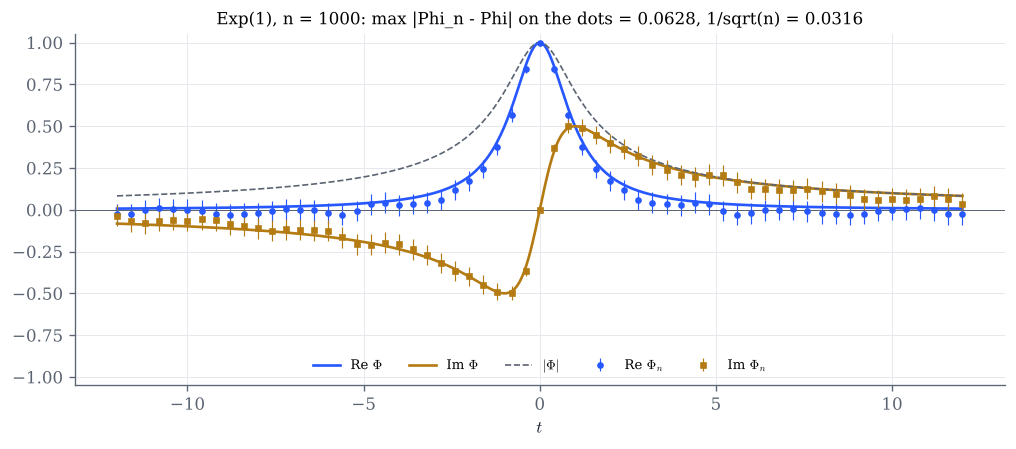

In [2]:
def ecf_demo(law="exponential", log10_n=3.0, seed=2026):
    L = LAWS[law]
    n = int(10 ** log10_n)
    x = L.sample(np.random.default_rng(seed), n)
    t = np.linspace(-12, 12, 801)
    ts = np.linspace(-12, 12, 61)
    p, e, se = L.cf(t), ecf(x, ts), ecf_standard_error(x, ts)
    fig, ax = plt.subplots(figsize=(10, 3.8))
    ax.plot(t, p.real, color=COBALT, label="Re $\\Phi$")
    ax.plot(t, p.imag, color=GOLD, label="Im $\\Phi$")
    ax.plot(t, np.abs(p), color=GREY, ls="--", lw=1, label="$|\\Phi|$")
    ax.errorbar(ts, e.real, yerr=2 * se, fmt="o", ms=3, color=COBALT, elinewidth=0.7, label="Re $\\Phi_n$")
    ax.errorbar(ts, e.imag, yerr=2 * se, fmt="s", ms=3, color=GOLD, elinewidth=0.7, label="Im $\\Phi_n$")
    ax.axhline(0, color=GREY, lw=0.6)
    err = np.abs(e - L.cf(ts)).max()
    ax.set(xlabel="$t$", ylim=(-1.05, 1.05),
           title=f"{L.name}, n = {n}: max |Phi_n - Phi| on the dots = {err:.4f}, 1/sqrt(n) = {1/math.sqrt(n):.4f}")
    ax.legend(fontsize=8, ncol=5, loc="lower center")
    plt.show()

ecf_demo()

In [3]:
# Explore: how fast does Phi_n approach Phi? Which laws have a real characteristic function?
interact(ecf_demo,
         law=Dropdown(options=list(LAWS), value="exponential", description="law"),
         log10_n=FloatSlider(value=3.0, min=1.0, max=5.5, step=0.25, continuous_update=False, description="log10 n"),
         seed=IntSlider(value=2026, min=0, max=3000, continuous_update=False, description="seed"));

## 2. Moments from derivatives at 0

If $X\in L^m$, then $\Phi_X^{(k)}(0)=i^k\,\mathbb E[X^k]$ for $k\le m$ (Theorem 10.14). Here $\Phi_X^{(k)}(0)$ is approximated by a
central difference on the $2p+1$ points $jh$, $|j|\le p$. Left: the error in $\mathbb E[X^k]$ as a function of the step $h$.
For large $h$ the truncation error of the difference dominates and falls like a power of $h$; for small $h$ the rounding
errors in the values of $\Phi_X$, of order $10^{-16}$, are divided by $h^k$ and grow. The best $h$ is in between, and it is
larger for larger $k$. Right: the four moments for the chosen $h$ (the vertical line), against the exact ones.

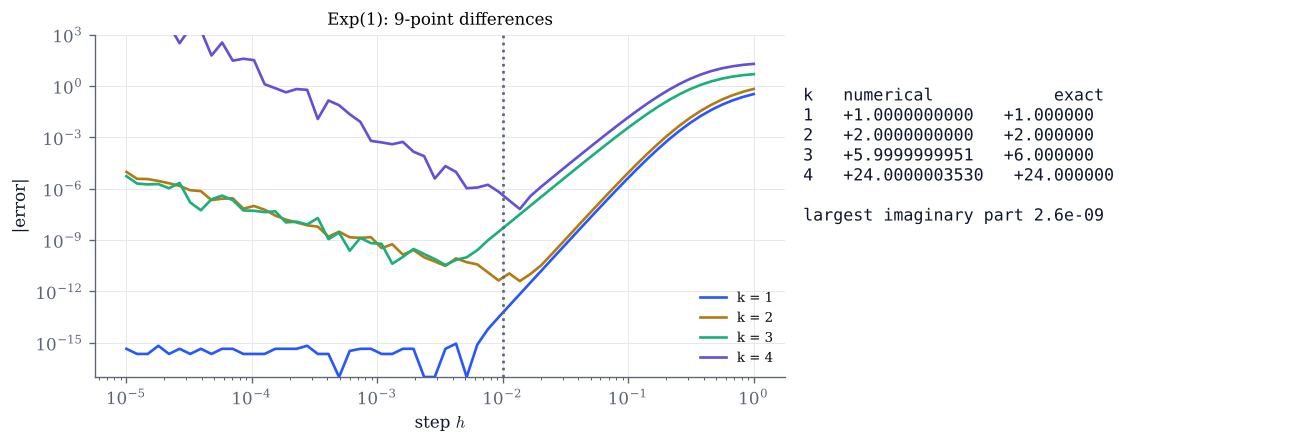

In [4]:
def moments_demo(law="exponential", log10_h=-2.0, p=4):
    L = LAWS[law]
    exact = np.array([L.moments[k] for k in range(1, 5)])
    hs = np.logspace(-5, 0, 60)
    errs = np.array([np.abs(moments_from_cf(L.cf, 4, h=h, p=p).real - exact) for h in hs])
    h = 10 ** log10_h
    m = moments_from_cf(L.cf, 4, h=h, p=p)
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [1.4, 1]})
    for k, col in zip(range(4), [COBALT, GOLD, GREEN, "#6250D6"]):
        a1.loglog(hs, np.maximum(errs[:, k], 1e-17), color=col, label=f"k = {k + 1}")
    a1.axvline(h, color=GREY, ls=":")
    a1.set(xlabel="step $h$", ylabel="|error|", ylim=(1e-17, 1e3), title=f"{L.name}: {2 * p + 1}-point differences")
    a1.legend(fontsize=8)
    a2.axis("off")
    rows = [f"k   numerical            exact"] + [
        f"{k}   {m[k - 1].real:+.10f}   {exact[k - 1]:+.6f}" for k in range(1, 5)]
    rows += ["", f"largest imaginary part {np.abs(m.imag).max():.1e}"]
    a2.text(0.0, 0.85, "\n".join(rows), family="monospace", fontsize=10, va="top", color=INK)
    fig.tight_layout()
    plt.show()

moments_demo()

In [5]:
# Explore: where is the best step for k = 4? What happens with p = 1 (three points)?
interact(moments_demo,
         law=Dropdown(options=[k for k in LAWS if LAWS[k].moments], value="exponential", description="law"),
         log10_h=FloatSlider(value=-2.0, min=-5.0, max=0.0, step=0.25, continuous_update=False, description="log10 h"),
         p=IntSlider(value=4, min=2, max=8, continuous_update=False, description="p"));

## 3. The inversion formula, truncated

If $\Phi_X$ is integrable, $f_X(x)=\frac1{2\pi}\int e^{-itx}\Phi_X(t)\,dt$ (Theorem 10.18). The demo computes the truncated integral
$f_L(x)=\frac1{2\pi}\int_{-L}^Le^{-itx}\Phi_X(t)\,dt$ by the trapezoidal rule, and compares it with the density. For an integrable
$\Phi_X$ the error is at most $\frac1\pi\int_L^\infty|\Phi_X|$, shown in the title. For the other laws (`uniform`, `exponential`,
`density 2x`, `product`) $f_L$ still converges where the density is continuous, but slowly; at a jump it tends to the mean of the
two one-sided limits, with the overshoot of the Gibbs phenomenon nearby; and at the singularity of `product` it grows without bound.

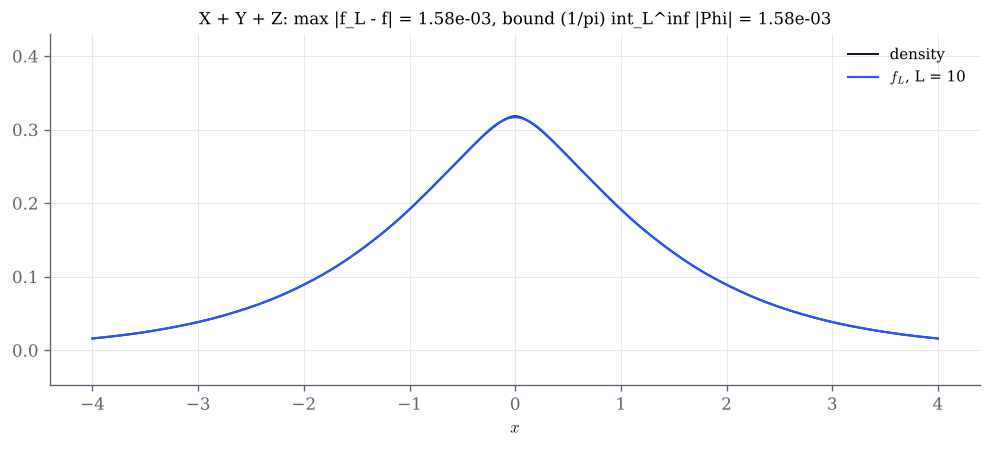

In [6]:
def inversion_demo(law="three products", log10_L=1.0):
    L = LAWS[law]
    Lt = 10 ** log10_L
    x = np.linspace(-4, 4, 801) if law != "density 2x" else np.linspace(-0.5, 1.5, 801)
    f = invert_density(L.cf, x, L=Lt, n=int(max(2000, 60 * Lt)))
    dens = L.density(x)
    fig, ax = plt.subplots(figsize=(10, 3.8))
    ax.plot(x, dens, color=INK, lw=1.2, label="density")
    ax.plot(x, f, color=COBALT, lw=1.3, label=f"$f_L$, L = {Lt:.3g}")
    ok = np.isfinite(dens)
    title = f"{L.name}: max |f_L - f| = {np.abs(f - dens)[ok].max():.2e}"
    if L.integrable_cf:
        tail = integrate.quad(lambda t: abs(L.cf(np.array(t))), Lt, np.inf, limit=200)[0] / math.pi
        title += f", bound (1/pi) int_L^inf |Phi| = {tail:.2e}"
    else:
        title += "  (Phi not integrable)"
    top = np.nanmax(np.where(ok, dens, np.nan))
    ax.set(xlabel="$x$", ylim=(-0.15 * top, 1.35 * top if law != "product" else 1.6), title=title)
    ax.legend(fontsize=9)
    plt.show()

inversion_demo()

In [7]:
# Explore: compare an integrable characteristic function (normal, laplace, cauchy, three products)
# with a non-integrable one (uniform, exponential, density 2x, product) as L grows.
interact(inversion_demo,
         law=Dropdown(options=[k for k in LAWS if LAWS[k].density is not None], value="three products", description="law"),
         log10_L=FloatSlider(value=1.0, min=0.0, max=2.5, step=0.1, continuous_update=False, description="log10 L"));

## 4. Sums of independent variables

If $X_1,\dots,X_n$ are independent with the same law, $\Phi_{X_1+\dots+X_n}=\Phi_{X_1}^n$ (Proposition 10.11): the convolution of the
densities becomes a power. Raising $\Phi$ to a power makes it decay faster, so it becomes integrable (for these laws, from $n=2$ on)
and the inversion formula recovers the density of the sum. The grey histogram is a simulation of the sum; the dashed green curve is
the Gaussian density with the same mean and variance, which the sum approaches as $n$ grows (the central limit theorem of
Chapter 17, proved with characteristic functions).

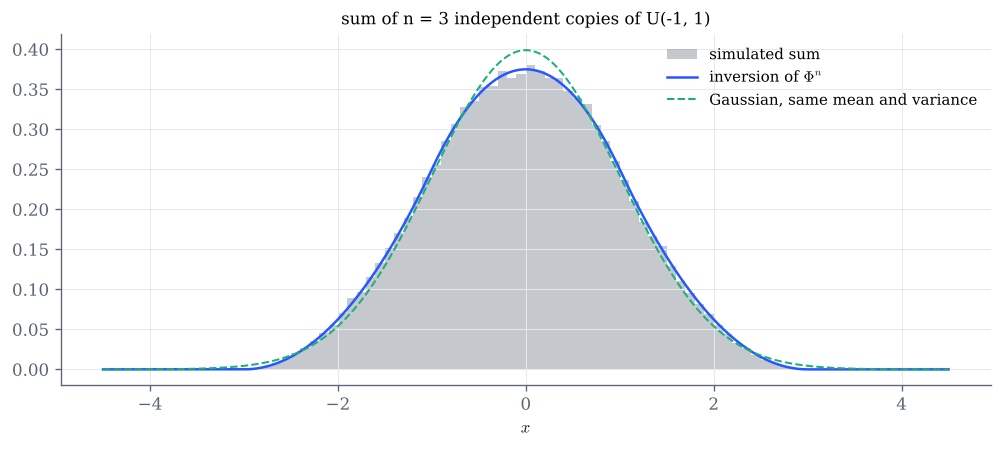

In [8]:
def sum_demo(law="uniform", n=3, seed=2026):
    L = LAWS[law]
    m1, m2 = L.moments[1], L.moments[2]
    mean, sd = n * m1, math.sqrt(n * (m2 - m1 ** 2))
    x = np.linspace(mean - 4.5 * sd, mean + 4.5 * sd, 601)
    phi_n = lambda t: L.cf(t) ** n
    f = invert_density(phi_n, x, L=60.0, n=24_000)
    s = L.sample(np.random.default_rng(seed), 200_000 * n).reshape(n, -1).sum(0)
    fig, ax = plt.subplots(figsize=(10, 3.8))
    ax.hist(s, bins=np.linspace(x[0], x[-1], 91), density=True, color=GREY, alpha=0.35, label="simulated sum")
    ax.plot(x, f, color=COBALT, lw=1.5, label="inversion of $\\Phi^n$")
    ax.plot(x, np.exp(-0.5 * ((x - mean) / sd) ** 2) / (sd * math.sqrt(2 * math.pi)), color=GREEN, ls="--",
            lw=1.2, label="Gaussian, same mean and variance")
    ax.set(xlabel="$x$", title=f"sum of n = {n} independent copies of {L.name}")
    ax.legend(fontsize=9)
    plt.show()

sum_demo()

In [9]:
# Explore: n = 1 is the law itself (the inversion integral then only converges slowly, if at all).
interact(sum_demo,
         law=Dropdown(options=["uniform", "exponential", "product", "density 2x", "laplace"], value="uniform", description="law"),
         n=IntSlider(value=3, min=1, max=12, continuous_update=False, description="n"),
         seed=IntSlider(value=2026, min=0, max=3000, continuous_update=False, description="seed"));

## 5. The independence criterion

$X$ and $Y$ are independent exactly when $\Phi_{(X,Y)}(s,t)=\Phi_X(s)\Phi_Y(t)$ for all $(s,t)$ (Theorem 10.20). On a sample, the
largest gap $|\Phi_n(s,t)-\Phi^X_n(s)\Phi^Y_n(t)|$ over a grid of $(s,t)$ is sampling noise, of order $n^{-1/2}$, for an independent
pair, and stays away from $0$ for a dependent one, even when $X$ and $Y$ are uncorrelated, as for $Y=X^2$ with $X$ uniform on $(-1,1)$.

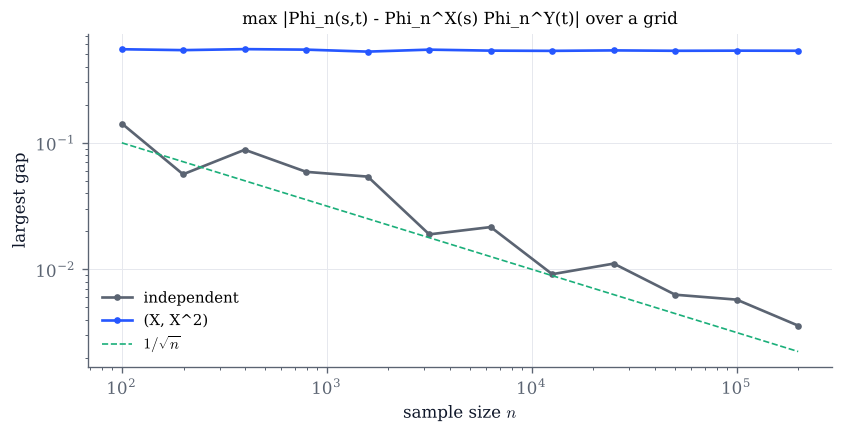

In [10]:
def pairs(kind, n, rng):
    x = rng.uniform(-1, 1, n)
    if kind == "independent":
        return x, rng.uniform(-1, 1, n)
    if kind == "(X, X^2)":
        return x, x ** 2
    if kind == "(X, |X| + noise)":
        return x, np.abs(x) + 0.5 * rng.standard_normal(n)
    return x, x + rng.standard_normal(n)                     # correlated

def criterion_demo(kind="(X, X^2)", seed=2026):
    s = np.linspace(-4, 4, 17)
    sizes = np.unique(np.geomspace(100, 200_000, 12).astype(int))
    fig, ax = plt.subplots(figsize=(8, 3.6))
    for k, col in zip(["independent", kind], [GREY, COBALT]):
        rng = np.random.default_rng(seed)
        gaps = [cf_independence_defect(*pairs(k, m, rng), s, s) for m in sizes]
        ax.loglog(sizes, gaps, marker="o", ms=3, color=col, label=k)
    ax.loglog(sizes, 1 / np.sqrt(sizes), color=GREEN, ls="--", lw=1, label="$1/\\sqrt{n}$")
    ax.set(xlabel="sample size $n$", ylabel="largest gap", title="max |Phi_n(s,t) - Phi_n^X(s) Phi_n^Y(t)| over a grid")
    ax.legend(fontsize=9)
    plt.show()

criterion_demo()

In [11]:
interact(criterion_demo,
         kind=Dropdown(options=["(X, X^2)", "(X, |X| + noise)", "(X, X + noise)"], value="(X, X^2)", description="pair"),
         seed=IntSlider(value=2026, min=0, max=3000, continuous_update=False, description="seed"));

## Things to try

- In section 1, choose `poisson` and look at $t=2\pi$: why is $\Phi(2\pi)=1$? Which laws have $|\Phi(t)|=1$ for some $t\ne0$?
- In section 1, how large must $n$ be for the dots to be within $0.01$ of the curve everywhere? Compare with $2/\sqrt n$.
- In section 2, choose `product` (the law of the worked exercise with $\Phi(t)=(1+t^2)^{-1/2}$) and check $\mathbb E[X^4]=9$. Which $h$ gives the
  most accurate fourth moment, and why is it larger than the best $h$ for the first moment?
- In section 3, choose `exponential` and increase $L$: does the overshoot near $0$ shrink? Compare its height with $\frac12+\frac1\pi\mathrm{Si}(\pi)\approx1.09$
  (Exercise 10.10).
- In section 3, choose `cauchy` with a small $L$: the error is dominated by the truncation bound. Then `laplace`: why does it need a much larger $L$?
- In section 4, take `exponential` and $n=5$: the sum has the Gamma law $\Gamma(5,1)$ (Exercise 10.6). Why is the Gaussian approximation worse than for `uniform`?